<a href="https://colab.research.google.com/github/roysam0963/COU07506-labs/blob/main/COU07506_Week04_240242494755.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 — Digital Signal Processing

## WEEK 4: z-Transform Laboratory — Poles, Zeros and Stability

**Name:** SADIKI MARKO MSUKWA

**Registration Number:** 240242494755

**Class:** BEng24COE

**Date:** 25 November 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 4 DSP Laboratory is ready!")

Week 4 DSP Laboratory is ready!


### Pre-lab Question (a)

**Question:**

Find the poles of the transfer function and determine whether the system is stable.

\[
H(z)=\frac{1}{1-0.9z^{-1}+0.81z^{-2}}
\]

**Answer:**

The poles are obtained by setting the denominator equal to zero.

\[
z^2-0.9z+0.81=0
\]

Using the quadratic formula:

\[
z=\frac{0.9\pm\sqrt{-2.43}}{2}
\]

Therefore:

\[
z=0.45\pm j0.7794
\]

The magnitude of each pole is approximately:

\[
|z|=0.9
\]

Since both poles have magnitudes less than 1, the system is stable.

**Conclusion:** The system is stable because all its poles lie inside the unit circle.

In [2]:
a = [1, -0.9, 0.81]
b = [1]

poles = np.roots(a)

print("Poles:", poles)
print("Pole magnitudes:", np.abs(poles))
print("System stable:", np.all(np.abs(poles) < 1))

Poles: [0.45+0.77942286j 0.45-0.77942286j]
Pole magnitudes: [0.9 0.9]
System stable: True


### Pre-lab Question (b)

**Question:**

Find the partial-fraction expansion of:

\[
X(z)=\frac{1}{(1-0.5z^{-1})(1-0.25z^{-1})}
\]

**Answer:**

Assume the partial-fraction expansion is:

\[
X(z)=\frac{A}{1-0.5z^{-1}}+\frac{B}{1-0.25z^{-1}}
\]

Multiplying by the denominator gives:

\[
1=A(1-0.25z^{-1})+B(1-0.5z^{-1})
\]

Comparing coefficients:

\[
A+B=1
\]

\[
0.25A+0.5B=0
\]

Solving the equations gives:

\[
A=2,\qquad B=-1
\]

Therefore, the partial-fraction expansion is:

\[
\boxed{X(z)=\frac{2}{1-0.5z^{-1}}-\frac{1}{1-0.25z^{-1}}}
\]

For a causal sequence, the inverse z-transform is:

\[
\boxed{x[n]=[2(0.5)^n-(0.25)^n]u[n]}
\]

In [3]:
b = [1]
a = [1, -0.75, 0.125]

residues, poles, direct = signal.residuez(b, a)

print("Residues:", residues)
print("Poles:", poles)
print("Direct term:", direct)

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct term: []


## Task 4.1: Pole-Zero Plot and Frequency Response

**Objective:**

To identify the poles and zeros of a digital system and analyse its frequency response using Python.

**Procedure:**

The `signal.tf2zpk()` function is used to calculate the zeros, poles and gain of a transfer function. The `signal.freqz()` function is used to calculate the frequency response.

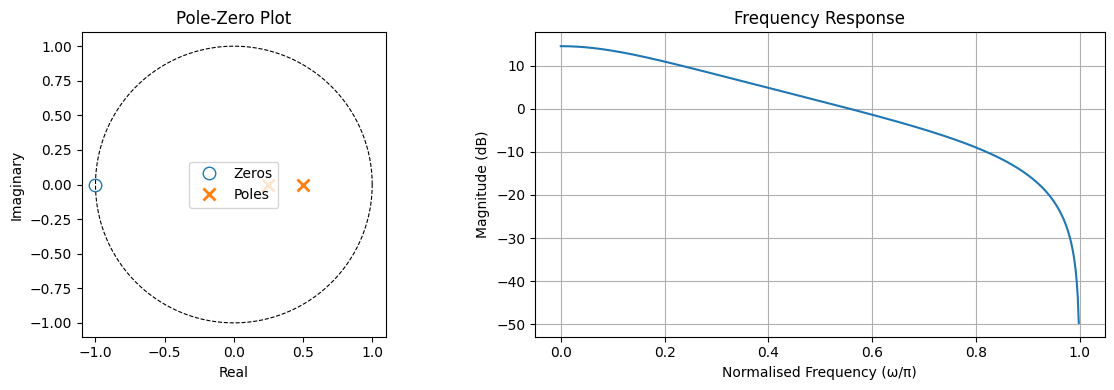

Zeros: [-1.]
Poles: [0.5  0.25]
System stable: True


In [4]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    theta = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(theta), np.sin(theta), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none",
            ms=9, label="Zeros")
    ax.plot(p.real, p.imag, "x", ms=9,
            mew=2, label="Poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Real")
    ax.set_ylabel("Imaginary")
    ax.set_title("Pole-Zero Plot")

    return z, p


b, a = [1, 1], [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.maximum(np.abs(H), 1e-12)))
ax2.set_xlabel("Normalised Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Frequency Response")
ax2.grid()

plt.tight_layout()
plt.show()

print("Zeros:", z)
print("Poles:", p)
print("System stable:", np.all(np.abs(p) < 1))

**Observation:**

The pole-zero plot shows one zero at \(z=-1\) and two poles at \(z=0.5\) and \(z=0.25\). All poles lie inside the unit circle, indicating that the system is stable.

The frequency response shows that the system has a higher response at low frequencies and a lower response near the Nyquist frequency. The zero at \(z=-1\) causes the response to become zero at the Nyquist frequency.

## Task 4.2: Inverse z-Transform using residuez

**Objective:**

To calculate the inverse z-transform using partial-fraction expansion and compare the result with the output obtained using `signal.lfilter()`.

**Procedure:**

The `signal.residuez()` function is used to obtain the residues and poles of the transfer function. The resulting sequence is then compared with the impulse response calculated using `signal.lfilter()`.

In [5]:
# Define the transfer function
b = [1]
a = [1, -0.75, 0.125]

# Find residues and poles
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)

# Calculate inverse z-transform
n = np.arange(10)

x_pf = np.zeros(len(n))

for ri, pi in zip(r, p):
    x_pf += ri * pi**n

# Calculate impulse response using lfilter
impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(b, a, impulse)

# Display results
print("\nInverse z-transform:", x_pf)
print("lfilter output:", x_lf)

print("\nAre the results equal?")
print(np.allclose(x_pf, x_lf))

Residues: [-1.  2.]
Poles: [0.25 0.5 ]

Inverse z-transform: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
lfilter output: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Are the results equal?
True


**Observation:**

The `residuez()` function successfully calculated the residues and poles of the transfer function. The inverse z-transform produced the same impulse response as `signal.lfilter()`.

The comparison returned `True`, confirming that both methods produce identical results. This verifies the correctness of the inverse z-transform calculation.

## Task 4.3: Effect of Pole Radius on System Response

**Objective:**

To investigate how the pole radius affects the impulse response, frequency response and stability of a digital system.

**Procedure:**

Different pole radii are used to observe how the system response changes. The pole angles are kept constant while the radius is varied.

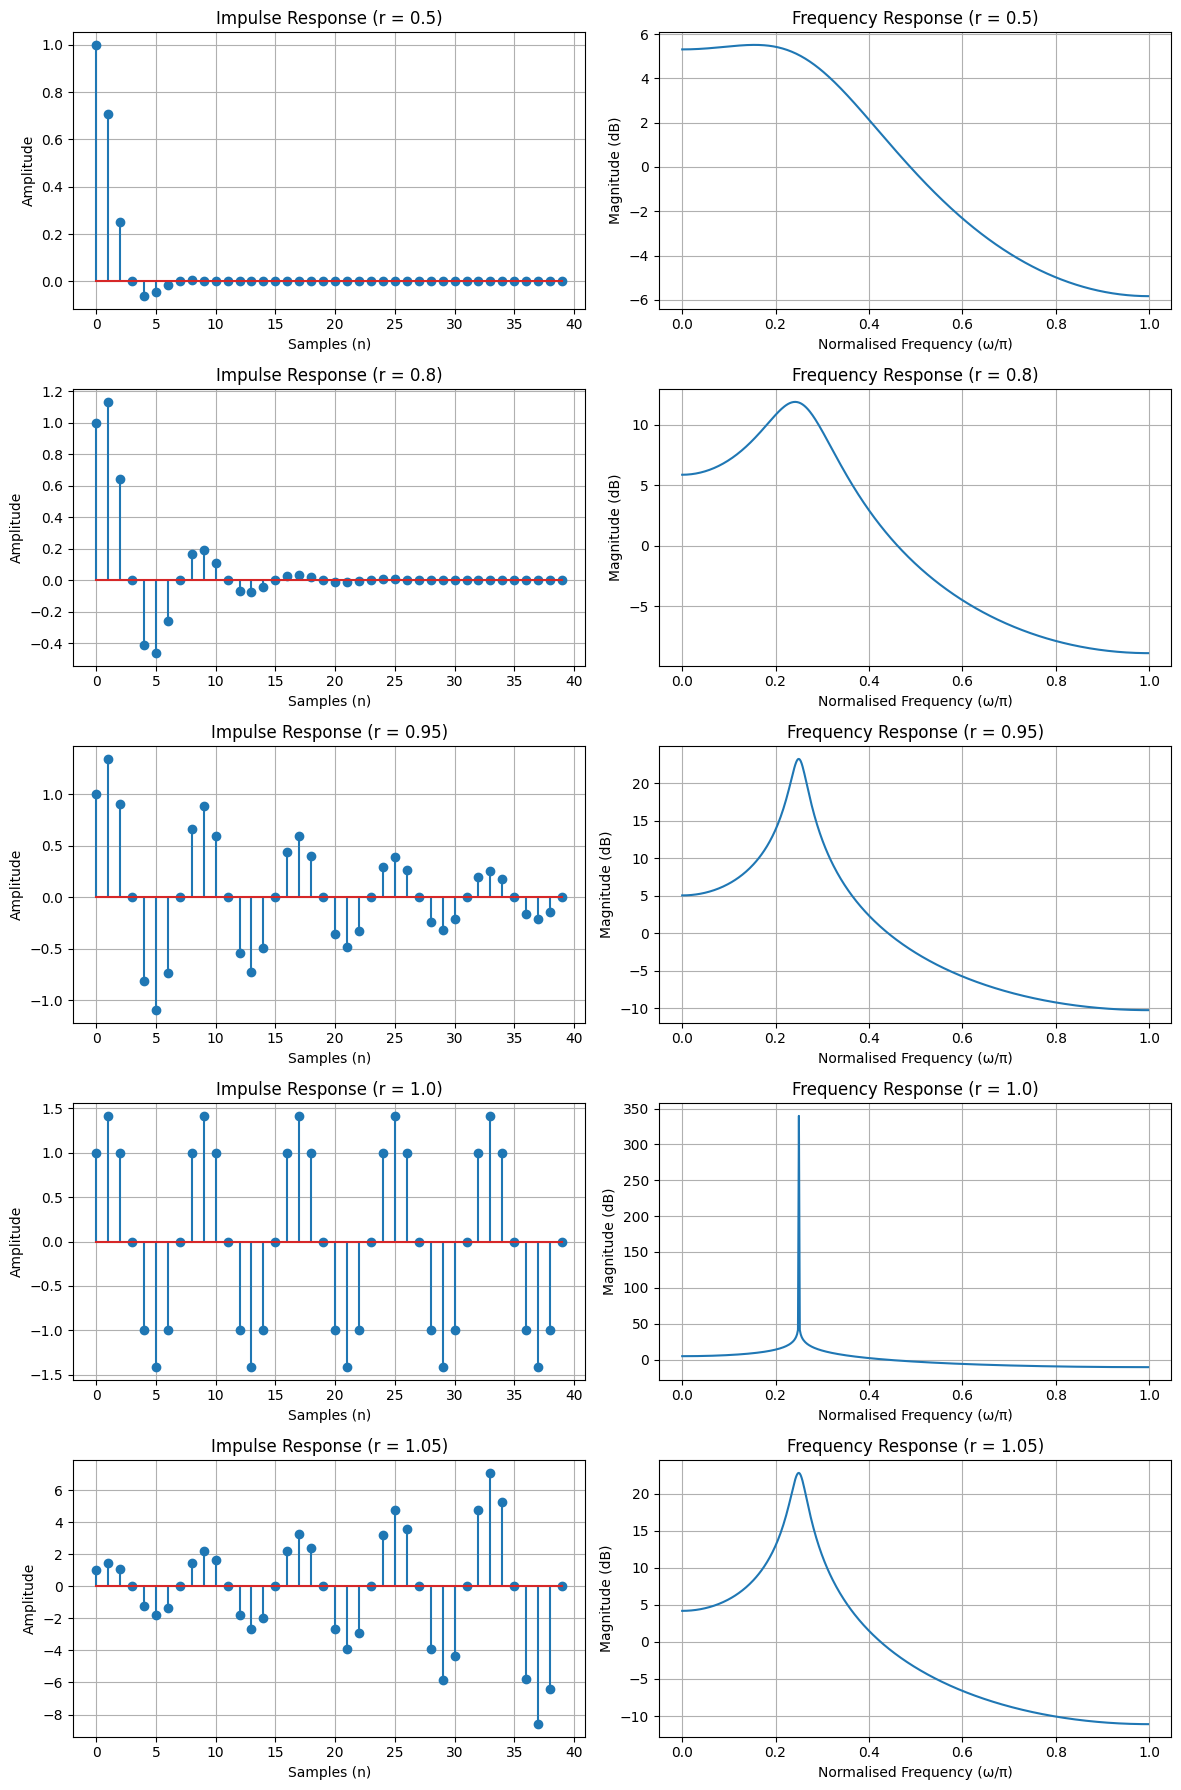

In [6]:
# Define pole radii
radii = [0.5, 0.8, 0.95, 1.0, 1.05]

# Define pole angle
theta = np.pi / 4

# Number of samples
n = np.arange(40)

# Create plots
fig, axes = plt.subplots(5, 2, figsize=(12, 18))

for i, r in enumerate(radii):

    # Denominator coefficients
    a = [1, -2*r*np.cos(theta), r**2]

    # Numerator
    b = [1]

    # Calculate impulse response
    impulse = np.zeros(40)
    impulse[0] = 1

    h = signal.lfilter(b, a, impulse)

    # Calculate frequency response
    w, H = signal.freqz(b, a, worN=512)

    # Plot impulse response
    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(f"Impulse Response (r = {r})")
    axes[i, 0].set_xlabel("Samples (n)")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid()

    # Plot frequency response
    axes[i, 1].plot(w/np.pi, 20*np.log10(np.maximum(np.abs(H), 1e-12)))
    axes[i, 1].set_title(f"Frequency Response (r = {r})")
    axes[i, 1].set_xlabel("Normalised Frequency (ω/π)")
    axes[i, 1].set_ylabel("Magnitude (dB)")
    axes[i, 1].grid()

plt.tight_layout()
plt.show()

**Observation:**

The pole radius has a significant effect on the impulse response and frequency response of a digital system.

- When \(r=0.5\), the impulse response decays quickly.
- When \(r=0.8\), the response decays more slowly.
- When \(r=0.95\), the response takes longer to decay and produces a sharper resonance peak.
- When \(r=1.0\), the oscillations remain sustained because the poles lie on the unit circle.
- When \(r=1.05\), the response increases with time, indicating an unstable system.

**Conclusion:**

As the pole radius approaches 1 from below, the resonance peak becomes sharper and the impulse response decays more slowly. A pole radius equal to or greater than 1 results in a system that is not BIBO stable.

## Task 4.4: Stability Classification of Different Systems

**Objective:**

To determine the stability of different digital systems by analysing their pole locations.

**Procedure:**

Four transfer functions are investigated. Their poles and zeros are calculated and plotted using the pole-zero diagram. Stability is determined by checking whether all poles lie inside the unit circle.

H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.94339811 0.94339811]
Stable: True
----------------------
H2
Zeros: [-1.]
Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]
Stable: False
----------------------
H3
Zeros: []
Poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]
Stable: False
----------------------
H4
Zeros: [-1.00000000e+00+0.j  8.32667268e-17+1.j  8.32667268e-17-1.j
  1.00000000e+00+0.j]
Poles: []
Pole magnitudes: []
Stable: True
----------------------


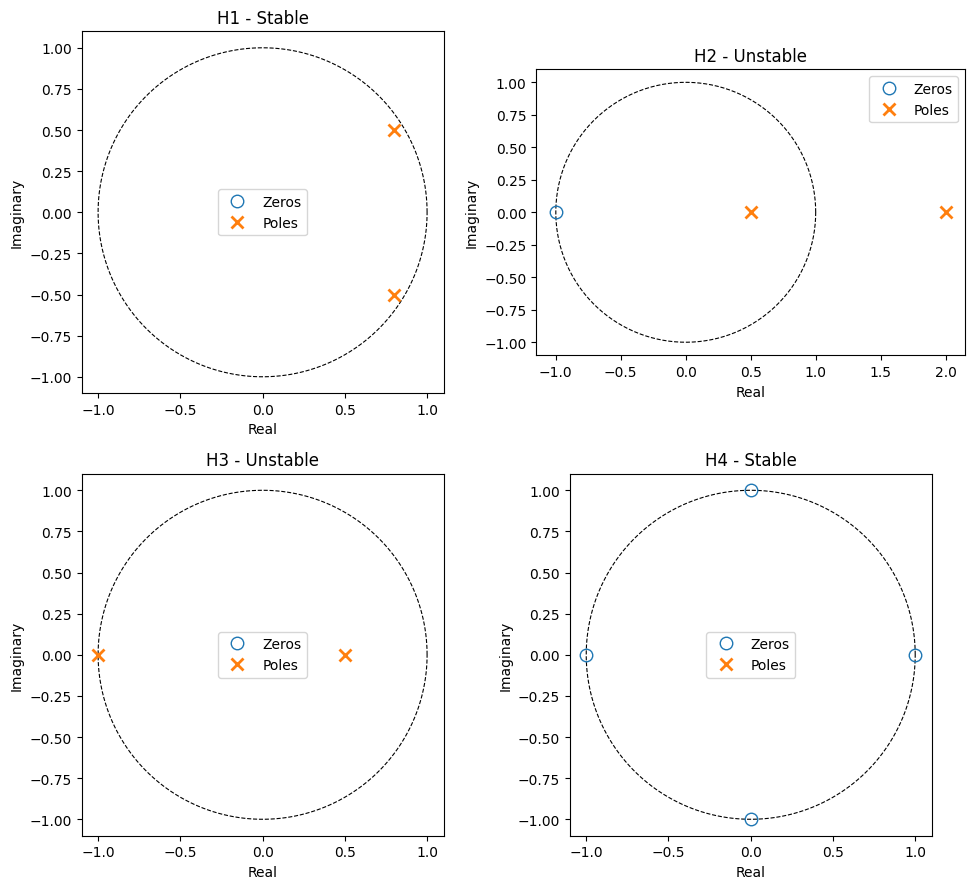

In [7]:
# Define four systems
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

# Create plots
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes = axes.flatten()

for ax, (name, (b, a)) in zip(axes, systems.items()):

    # Calculate poles and zeros
    z, p = zplane(b, a, ax)

    # Determine stability
    stable = np.all(np.abs(p) < 1)

    ax.set_title(f"{name} - {'Stable' if stable else 'Unstable'}")

    print(name)
    print("Zeros:", z)
    print("Poles:", p)
    print("Pole magnitudes:", np.abs(p))
    print("Stable:", stable)
    print("----------------------")

plt.tight_layout()
plt.show()

**Observation:**

The pole-zero analysis produced the following stability results:

1. **H1:** Stable because all poles lie inside the unit circle.
2. **H2:** Unstable because it has poles outside the unit circle.
3. **H3:** Unstable because one pole lies outside the unit circle.
4. **H4:** Stable because it is an FIR system with a finite impulse response.

**Conclusion:**

The stability of a digital system can be determined by examining its pole locations. A causal rational system is BIBO stable when all its poles lie strictly inside the unit circle. FIR systems are stable when their coefficients are finite.

## Task 4.5: Designing a Digital Resonator

**Objective:**

To design a digital resonator with a resonant frequency of 1 kHz and analyse its frequency response.

**Design Specifications:**

- Sampling frequency: 8000 Hz
- Resonant frequency: 1000 Hz
- Pole radius: 0.97
- Zeros: \(z=+1\) and \(z=-1\)

**Procedure:**

The poles are placed near the unit circle at the required resonant frequency. Zeros are placed at \(z=+1\) and \(z=-1\) to suppress the DC and Nyquist frequencies.

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Pole magnitudes: [0.97 0.97]


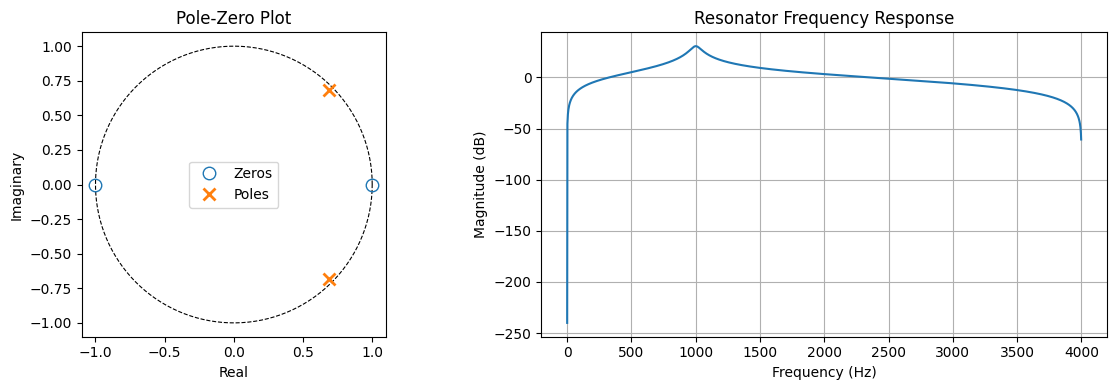

Resonant frequency: 1000 Hz
System stable: True


In [8]:
# Resonator design specifications
fs = 8000
f0 = 1000
r = 0.97

# Calculate pole angle
theta = 2 * np.pi * f0 / fs

# Define numerator (zeros at +1 and -1)
b = [1, 0, -1]

# Define denominator (poles)
a = [1, -2*r*np.cos(theta), r**2]

# Calculate poles and zeros
z, p, k = signal.tf2zpk(b, a)

print("Zeros:", z)
print("Poles:", p)
print("Pole magnitudes:", np.abs(p))

# Plot pole-zero diagram and frequency response
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=2048, fs=fs)

ax2.plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12)))
ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid()

plt.tight_layout()
plt.show()

print("Resonant frequency:", f0, "Hz")
print("System stable:", np.all(np.abs(p) < 1))

In [9]:
# Generate white noise
np.random.seed(0)

duration = 2
x = np.random.randn(fs * duration)

print("Sampling frequency:", fs, "Hz")
print("Number of samples:", len(x))
print("Duration:", duration, "seconds")

Sampling frequency: 8000 Hz
Number of samples: 16000
Duration: 2 seconds


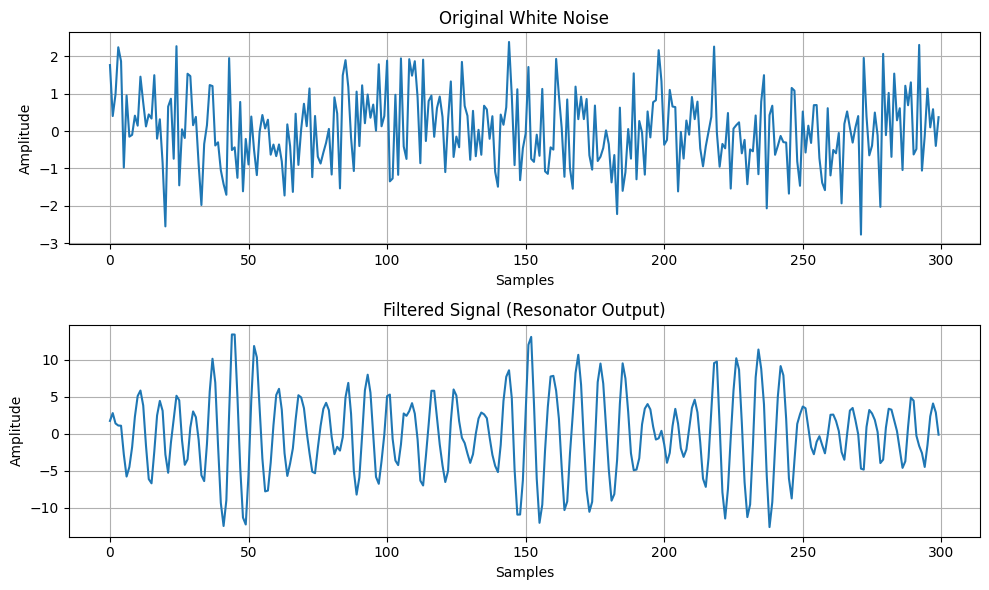

In [10]:
# Apply resonator to white noise
y = signal.lfilter(b, a, x)

# Plot input and output signals
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].plot(x[:300])
axes[0].set_title("Original White Noise")
axes[0].set_xlabel("Samples")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

axes[1].plot(y[:300])
axes[1].set_title("Filtered Signal (Resonator Output)")
axes[1].set_xlabel("Samples")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()

In [11]:
from IPython.display import Audio, display

print("Original White Noise:")
display(Audio(x, rate=fs))

print("Resonator Output:")
display(Audio(y, rate=fs))

Original White Noise:


Resonator Output:


**Observation:**

The resonator filter was successfully applied to the white noise signal. The original white noise contained a wide range of frequency components, while the filtered output emphasized frequencies around 1000 Hz.

The pole radius of 0.97 produced a sharp resonance peak near the desired frequency. The zeros at \(z=+1\) and \(z=-1\) suppressed the DC and Nyquist frequencies.

**Conclusion:**

The designed digital resonator successfully emphasized the 1 kHz frequency component and demonstrated the effect of pole and zero placement on a digital filter.

### Analysis Question 1

**Question:**

How does the pole radius affect the resonance bandwidth in Task 4.3?

**Answer:**

As the pole radius approaches 1 from below, the resonance peak becomes sharper and the resonance bandwidth becomes narrower.

A smaller pole radius produces a wider bandwidth and a less sharp resonance peak.

Therefore, the resonance bandwidth decreases as the pole radius increases towards 1.

### Analysis Question 2

**Question:**

What happens when a pole lies exactly on the unit circle?

**Answer:**

When a pole lies exactly on the unit circle, its magnitude is equal to 1.

The impulse response does not decay with time. It may produce sustained oscillations or a constant component.

Therefore, a causal system with a pole on the unit circle is not BIBO stable.

### Analysis Question 3

**Question:**

Why are zeros placed at \(z=+1\) and \(z=-1\) in Task 4.5?

**Answer:**

The zero at \(z=+1\) suppresses the DC frequency (0 Hz), while the zero at \(z=-1\) suppresses the Nyquist frequency (4000 Hz).

These zeros reduce the response at the two frequency limits and help produce a band-pass resonator response.

### Analysis Question 4

**Question:**

Classify the systems in Task 4.4 as stable or unstable and explain your answers.

**Answer:**

1. **H1:** Stable because all its poles lie inside the unit circle.
2. **H2:** Unstable because it has poles outside the unit circle.
3. **H3:** Unstable because one pole lies outside the unit circle.
4. **H4:** Stable because it is an FIR system with a finite impulse response.

**Conclusion:**

A causal rational system is BIBO stable when all its poles lie strictly inside the unit circle. FIR systems with finite coefficients are also BIBO stable.

## AI Use Statement

Artificial Intelligence tools were used to assist with understanding DSP concepts, explaining Python code, debugging errors and improving the presentation of laboratory answers. All practical exercises were executed and reviewed by the student.